# Лабораторная работа №2: Детекция и сегментация объектов

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Проверить разметку и распределения объектов.
- Дообучить компактный segmentation baseline.
- Сравнить аугментации и проанализировать ошибки.


## Теоретическая часть

В детекции модель предсказывает классы и bounding boxes, в сегментации — метку каждого пикселя. Для класса $c$ качество сегментации измеряет $IoU_c=|P_c\cap G_c|/|P_c\cup G_c|$. Для детекции mAP усредняет AP по классам и порогам IoU.

![Segmentation example](https://pytorch.org/vision/main/_images/sphx_glr_plot_visualization_utils_008.png)


### Математическая постановка

Составная функция потерь может иметь вид
$$\mathcal L=\mathcal L_{cls}+\lambda_{box}\mathcal L_{box}+\lambda_{mask}\mathcal L_{mask}.$$
Разбиение должно выполняться по исходным объектам/сериям, иначе соседние кадры дают утечку.


### Материалы

- [Torchvision segmentation models](https://pytorch.org/vision/stable/models.html#semantic-segmentation)
- [COCO metrics](https://cocodataset.org/#detection-eval)
- [Oxford-IIIT Pet Dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Проверить разметку и распределения объектов.
2. Дообучить компактный segmentation baseline.
3. Сравнить аугментации и проанализировать ошибки.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** LRASPP-MobileNetV3 или FCN-ResNet50, mixed precision.
- **Ограничение данных:** Oxford-IIIT Pet или до 2 000 изображений; в smoke-режиме — синтетический датасет.
- **Fallback:** замороженный backbone и 256 px.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 31
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
DATA_ROOT = Path.cwd() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cpu', 'fast_dev_run': False, 'data_root': 'c:\\Anton\\16 триместр\\SOTA\\lab2\\data'}


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

In [3]:
# Библиотеки
import torch
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.datasets import OxfordIIITPet
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as TF

import matplotlib.pyplot as plt

import torch.nn as nn
from torchvision.models.segmentation import (
    lraspp_mobilenet_v3_large,
    LRASPP_MobileNet_V3_Large_Weights,
)

### Маски Oxford-IIIT Pet

*Вес: 1 балл.*

**Постановка.** Сегментатор обучается на реальной пиксельной разметке.

Выполните следующие действия:
1. Загрузите trainval Oxford-IIIT Pet и совместно масштабируйте изображение и маску.
2. Убедитесь, что интерполяция маски сохраняет классы.

**Результат.** Датасет ds и преобразования img_tf, mask_tf.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [4]:
IMG_SIZE = 256


# Базовый Oxford-IIIT Pet trainval с пиксельной разметкой (trimap)
base_ds = OxfordIIITPet(
    root=DATA_ROOT,
    split="trainval",
    target_types="segmentation",
    download=True,
)


# Преобразование изображения
img_tf = transforms.Compose([
    transforms.Resize(
        (IMG_SIZE, IMG_SIZE),
        interpolation=InterpolationMode.BILINEAR,
    ),
    transforms.ToTensor(),
])


# Преобразование маски.
# NEAREST принципиально важен: классы маски нельзя смешивать.
mask_tf = transforms.Compose([
    transforms.Resize(
        (IMG_SIZE, IMG_SIZE),
        interpolation=InterpolationMode.NEAREST,
    ),
    transforms.PILToTensor(),
    transforms.Lambda(lambda x: x.squeeze(0).long()),
])


class OxfordPetSegmentation(Dataset):
    def __init__(self, base_dataset, img_tf=None, mask_tf=None):
        self.base_dataset = base_dataset
        self.img_tf = img_tf
        self.mask_tf = mask_tf

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        image, mask = self.base_dataset[idx]

        if self.img_tf is not None:
            image = self.img_tf(image)

        if self.mask_tf is not None:
            mask = self.mask_tf(mask)

        return image, mask


ds = OxfordPetSegmentation(
    base_dataset=base_ds,
    img_tf=img_tf,
    mask_tf=mask_tf,
)


# Проверка результата
image, mask = ds[0]

print("Dataset size:", len(ds))
print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Mask dtype:", mask.dtype)
print("Mask classes:", torch.unique(mask).tolist())

assert image.shape == (3, IMG_SIZE, IMG_SIZE)
assert mask.shape == (IMG_SIZE, IMG_SIZE)
assert mask.dtype == torch.long

# После NEAREST в маске должны оставаться только исходные дискретные классы.
assert set(torch.unique(mask).tolist()).issubset({1, 2, 3})

print("Mask interpolation check: OK")

Dataset size: 3680
Image shape: torch.Size([3, 256, 256])
Mask shape: torch.Size([256, 256])
Mask dtype: torch.int64
Mask classes: [1, 2, 3]
Mask interpolation check: OK


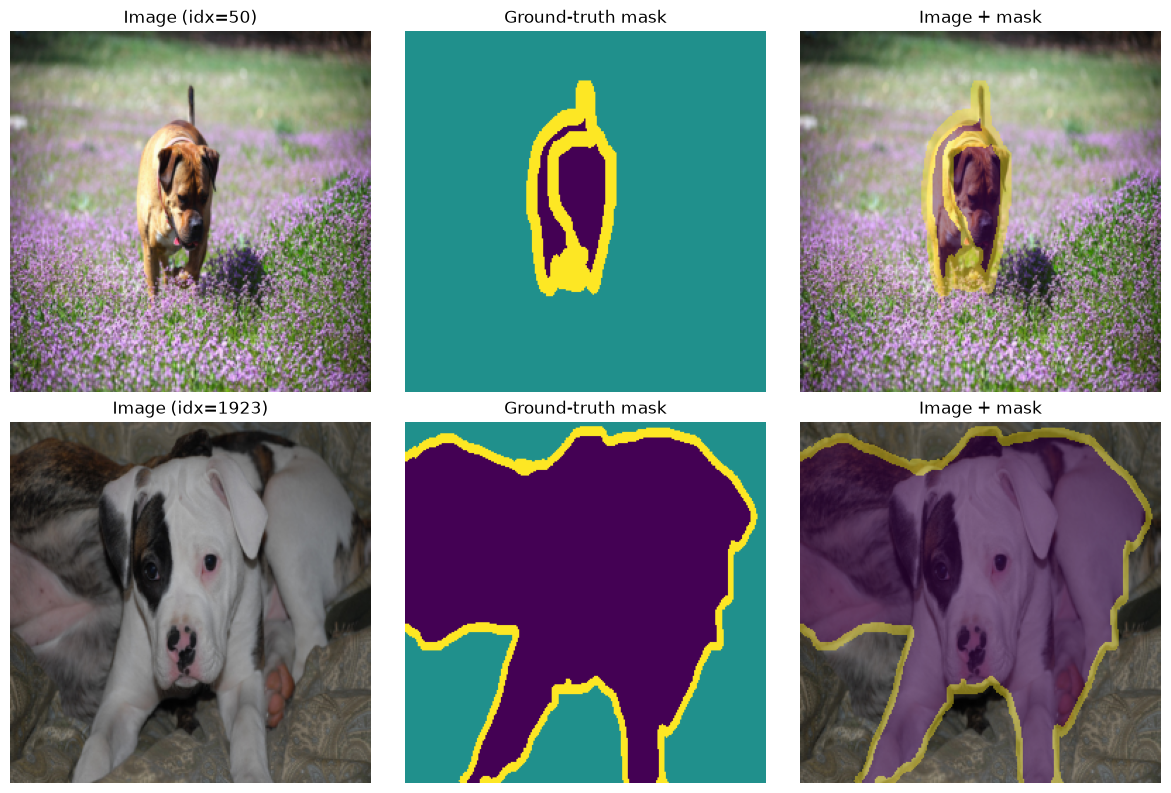

In [5]:
# Визуализация случайных примеров с масками
def visualize_random_samples(dataset, n=2, alpha=0.45):
    indices = random.sample(range(len(dataset)), n)

    fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))

    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, idx in enumerate(indices):
        image, mask = dataset[idx]

        # Tensor [C, H, W] -> numpy [H, W, C]
        image_np = image.permute(1, 2, 0).numpy()

        # Tensor [H, W] -> numpy [H, W]
        mask_np = mask.numpy()

        # Исходное изображение
        axes[row, 0].imshow(image_np)
        axes[row, 0].set_title(f"Image (idx={idx})")
        axes[row, 0].axis("off")

        # Маска
        axes[row, 1].imshow(mask_np)
        axes[row, 1].set_title("Ground-truth mask")
        axes[row, 1].axis("off")

        # Наложение маски на изображение
        axes[row, 2].imshow(image_np)
        axes[row, 2].imshow(
            np.ma.masked_where(mask_np == 2, mask_np),
            alpha=alpha
        )
        axes[row, 2].set_title("Image + mask")
        axes[row, 2].axis("off")

    plt.tight_layout()
    plt.show()


visualize_random_samples(ds, n=2)

### Разделение и кодирование меток

*Вес: 1 балл.*

**Постановка.** Оценка на validation требует непересекающихся индексов и корректных категориальных меток.

Выполните следующие действия:
1. Разделите trainval на train и validation.
2. Перекодируйте исходные метки 1–3 в 0–2 и соберите загрузчики.

**Результат.** train_ds, val_ds, loader, val_loader и normalize_mask.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [6]:
# ---------------------------------------------------------
# 1. Нормализация меток маски: 1,2,3 -> 0,1,2
# ---------------------------------------------------------

def normalize_mask(mask):
    """
    Oxford-IIIT Pet:
        1 -> 0
        2 -> 1
        3 -> 2
    """
    return mask.long() - 1


class NormalizedMaskDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        image, mask = self.dataset[idx]
        mask = normalize_mask(mask)
        return image, mask


# ---------------------------------------------------------
# 2. Воспроизводимое train/validation-разделение
# ---------------------------------------------------------

N = len(ds)

generator = torch.Generator().manual_seed(SEED)

indices = torch.randperm(N, generator=generator).tolist()

# В полном режиме используем весь trainval.
# В FAST_DEV_RUN берём небольшую подвыборку только для проверки pipeline.
if FAST_DEV_RUN:
    DEV_TOTAL = min(200, N)
    indices = indices[:DEV_TOTAL]

split_idx = int(0.8 * len(indices))

train_indices = indices[:split_idx]
val_indices = indices[split_idx:]


# Проверяем отсутствие пересечения
assert set(train_indices).isdisjoint(set(val_indices))

# ---------------------------------------------------------
# 3. Создаём train/validation datasets
# ---------------------------------------------------------

train_ds = NormalizedMaskDataset(
    Subset(ds, train_indices)
)

val_ds = NormalizedMaskDataset(
    Subset(ds, val_indices)
)


# ---------------------------------------------------------
# 4. DataLoader
# ---------------------------------------------------------

BATCH_SIZE = 4 if FAST_DEV_RUN else 8

loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE == "cuda"),
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE == "cuda"),
)


# ---------------------------------------------------------
# 5. Проверки
# ---------------------------------------------------------

x, y = next(iter(loader))

assert x.ndim == 4
assert y.ndim == 3

assert x.shape[0] <= BATCH_SIZE
assert y.min().item() >= 0
assert y.max().item() <= 2

assert len(set(train_indices) & set(val_indices)) == 0

# ---------------------------------------------------------
# 6. Сохраняем информацию об эксперименте
# ---------------------------------------------------------

split_info = {
    "seed": SEED,
    "fast_dev_run": FAST_DEV_RUN,
    "full_dataset_size": N,
    "train_size": len(train_ds),
    "val_size": len(val_ds),
    "train_indices": train_indices,
    "val_indices": val_indices,
    "batch_size": BATCH_SIZE,
    "num_classes": 3,
    "mask_mapping": {
        "1": 0,
        "2": 1,
        "3": 2,
    },
}

with open(ARTIFACTS / "split_info.json", "w", encoding="utf-8") as f:
    json.dump(split_info, f, ensure_ascii=False, indent=2)

print("Split information saved to:", ARTIFACTS / "split_info.json")

Split information saved to: artifacts\split_info.json


In [7]:
with open(ARTIFACTS / "split_info.json", "r", encoding="utf-8") as f:
    split_info = json.load(f)

for key, value in split_info.items():
    if key in ("train_indices", "val_indices"):
        print(f"{key}: {len(value)} индексов")
    else:
        print(f"{key}: {value}")

seed: 31
fast_dev_run: False
full_dataset_size: 3680
train_size: 2944
val_size: 736
train_indices: 2944 индексов
val_indices: 736 индексов
batch_size: 8
num_classes: 3
mask_mapping: {'1': 0, '2': 1, '3': 2}


### Сегментатор и IoU

*Вес: 1 балл.*

**Постановка.** Пиксельная модель предсказывает логиты для каждого класса.

Выполните следующие действия:
1. Замените головы LRASPP на трёхклассовые.
2. Реализуйте IoU по пересечению и объединению масок.

**Результат.** Объект model и функция mean_iou.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [8]:
NUM_CLASSES = 3

# ---------------------------------------------------------
# 1. Создаём pretrained LRASPP-MobileNetV3
# ---------------------------------------------------------

weights = LRASPP_MobileNet_V3_Large_Weights.DEFAULT

model = lraspp_mobilenet_v3_large(
    weights=weights,
)

# Заменяем segmentation head на трёхклассовый.
# LRASPP head имеет два классификатора:
# low_classifier и high_classifier.
model.classifier.low_classifier = nn.Conv2d(
    in_channels=40,
    out_channels=NUM_CLASSES,
    kernel_size=1,
)

model.classifier.high_classifier = nn.Conv2d(
    in_channels=128,
    out_channels=NUM_CLASSES,
    kernel_size=1,
)

model = model.to(DEVICE)


# ---------------------------------------------------------
# 2. IoU
# ---------------------------------------------------------

def mean_iou(pred, target, num_classes=NUM_CLASSES):
    ious = []

    for cls in range(num_classes):
        pred_cls = pred == cls
        target_cls = target == cls

        intersection = (pred_cls & target_cls).sum().float()
        union = (pred_cls | target_cls).sum().float()

        # Если класса нет ни в prediction, ни в target,
        # он не участвует в среднем.
        if union == 0:
            continue

        iou = intersection / union
        ious.append(iou)

    if len(ious) == 0:
        return torch.tensor(1.0, device=pred.device)

    return torch.stack(ious).mean()


# ---------------------------------------------------------
# 3. Проверяем forward pass
# ---------------------------------------------------------

model.eval()

with torch.no_grad():
    sample_images, sample_masks = next(iter(val_loader))
    sample_images = sample_images.to(DEVICE)

    output = model(sample_images)["out"]

print("Input shape:", tuple(sample_images.shape))
print("Output shape:", tuple(output.shape))

assert output.shape[1] == NUM_CLASSES

# Логиты -> классы
sample_pred = output.argmax(dim=1)

print("Prediction shape:", tuple(sample_pred.shape))
print("Prediction classes:", torch.unique(sample_pred).tolist())

# Проверяем IoU
sample_masks = sample_masks.to(DEVICE)

score = mean_iou(sample_pred, sample_masks)
print("\nПроверяем работу функции на необученной модели:")
print("Mean IoU:", float(score))

Input shape: (8, 3, 256, 256)
Output shape: (8, 3, 256, 256)
Prediction shape: (8, 256, 256)
Prediction classes: [0, 1, 2]

Проверяем работу функции на необученной модели:
Mean IoU: 0.2077687531709671


### Оптимизация сегментатора

*Вес: 1 балл.*

**Постановка.** Cross-entropy на масках задаёт обучающий сигнал каждому пикселю.

Выполните следующие действия:
1. Реализуйте шаг AdamW с обратным распространением.
2. Обучите модель установленное число эпох.

**Результат.** Функция train_one_epoch и массив history реальных значений loss.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [9]:
# Оптимизация сегментатора
#
# FAST_DEV_RUN=True:
#   - короткий прогон;
#   - checkpoint и финальные веса НЕ сохраняются.
#
# FAST_DEV_RUN=False:
#   - сохраняется checkpoint после каждой эпохи;
#   - после полного обучения сохраняются финальные веса и history;
#   - при повторном запуске обучение продолжается с последнего checkpoint.

# =========================================================
# Конфигурация
# =========================================================

NUM_EPOCHS = 2 if FAST_DEV_RUN else 5
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

RUN_TAG = "fast" if FAST_DEV_RUN else "full"

CHECKPOINT_PATH = ARTIFACTS / f"segmentation_training_checkpoint_{RUN_TAG}.pt"
FINAL_WEIGHTS_PATH = ARTIFACTS / f"segmentation_model_final_{RUN_TAG}.pt"
FINAL_HISTORY_PATH = ARTIFACTS / f"segmentation_training_{RUN_TAG}.json"


# =========================================================
# На CPU используем fallback:
# замораживаем backbone и обучаем segmentation head.
# На CUDA обучаем всю модель.
# =========================================================

if DEVICE == "cpu":
    for param in model.backbone.parameters():
        param.requires_grad = False

    TRAIN_MODE = "frozen_backbone"
else:
    for param in model.backbone.parameters():
        param.requires_grad = True

    TRAIN_MODE = "full_finetune"


trainable_parameters = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

total_parameters = sum(
    p.numel() for p in model.parameters()
)

# =========================================================
# Loss + AdamW
# =========================================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)


# =========================================================
# Один train epoch
# =========================================================

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()

    # При frozen backbone переводим backbone в eval(),
    # чтобы BatchNorm не обновлял статистики.
    if TRAIN_MODE == "frozen_backbone":
        model.backbone.eval()
        model.classifier.train()

    running_loss = 0.0
    total_samples = 0

    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)["out"]

        loss = criterion(outputs, masks)

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)

        running_loss += loss.item() * batch_size
        total_samples += batch_size

    return running_loss / total_samples


# =========================================================
# Validation loss
# =========================================================

@torch.no_grad()
def evaluate_loss(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    total_samples = 0

    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        outputs = model(images)["out"]

        loss = criterion(outputs, masks)

        batch_size = images.size(0)

        running_loss += loss.item() * batch_size
        total_samples += batch_size

    return running_loss / total_samples


# =========================================================
# Если финальная модель уже полностью обучена —
# просто загружаем её и не запускаем обучение заново.
# =========================================================

if (
    not FAST_DEV_RUN
    and FINAL_WEIGHTS_PATH.exists()
    and FINAL_HISTORY_PATH.exists()
):
    print("Final trained model already exists.")
    print("Loading:", FINAL_WEIGHTS_PATH)

    model.load_state_dict(
        torch.load(
            FINAL_WEIGHTS_PATH,
            map_location=DEVICE,
            weights_only=True,
        )
    )

    with open(FINAL_HISTORY_PATH, "r", encoding="utf-8") as f:
        result = json.load(f)

    history = result["history"]

    print(
        f"Loaded completed training: "
        f"{result['epochs']} epochs"
    )

else:

    # =====================================================
    # Загружаем последний checkpoint, если он есть
    # =====================================================

    history = []
    start_epoch = 1
    best_val_loss = float("inf")
    start_time = time.time()

    if not FAST_DEV_RUN and CHECKPOINT_PATH.exists():

        print("Checkpoint found.")
        print("Loading:", CHECKPOINT_PATH)

        checkpoint = torch.load(
            CHECKPOINT_PATH,
            map_location=DEVICE,
            weights_only=False,
        )

        model.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

        start_epoch = checkpoint["epoch"] + 1
        history = checkpoint.get("history", [])
        best_val_loss = checkpoint.get(
            "best_val_loss",
            float("inf")
        )

        print(
            f"Continuing from epoch "
            f"{checkpoint['epoch']}"
        )

    else:
        print("Starting training from epoch 1.")

    # =====================================================
    # Training loop
    # =====================================================

    for epoch in range(start_epoch, NUM_EPOCHS + 1):

        epoch_start = time.time()

        train_loss = train_one_epoch(
            model=model,
            loader=loader,
            optimizer=optimizer,
            criterion=criterion,
            device=DEVICE,
        )

        val_loss = evaluate_loss(
            model=model,
            loader=val_loader,
            criterion=criterion,
            device=DEVICE,
        )

        epoch_time = time.time() - epoch_start

        epoch_result = {
            "epoch": epoch,
            "train_loss": float(train_loss),
            "val_loss": float(val_loss),
            "time_seconds": float(epoch_time),
        }

        history.append(epoch_result)

        best_val_loss = min(best_val_loss, val_loss)

        print(
            f"Epoch {epoch}/{NUM_EPOCHS} | "
            f"train_loss={train_loss:.5f} | "
            f"val_loss={val_loss:.5f} | "
            f"time={epoch_time:.1f}s"
        )

        # =================================================
        # Промежуточный checkpoint
        # =================================================

        checkpoint = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "history": history,
            "config": {
                "seed": SEED,
                "device": DEVICE,
                "mode": TRAIN_MODE,
                "epochs": NUM_EPOCHS,
                "learning_rate": LEARNING_RATE,
                "weight_decay": WEIGHT_DECAY,
                "num_classes": NUM_CLASSES,
            },
        }

        torch.save(
            checkpoint,
            CHECKPOINT_PATH,
        )

        print(
            "Checkpoint saved:",
            CHECKPOINT_PATH,
        )

    total_time = time.time() - start_time

    # =================================================
    # Обучение закончено.
    # Финальные веса сохраняем только один раз.
    # =================================================

    if not FINAL_WEIGHTS_PATH.exists() or FAST_DEV_RUN:

        torch.save(
            model.state_dict(),
            FINAL_WEIGHTS_PATH,
        )

        print(
            "Final model saved:",
            FINAL_WEIGHTS_PATH,
        )

    else:
        print(
            "Final model already exists, "
            "not overwriting it."
        )

    result = {
        "mode": TRAIN_MODE,
        "epochs": NUM_EPOCHS,
        "best_epoch": min(
            history,
            key=lambda x: x["val_loss"]
        )["epoch"],
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "total_parameters": total_parameters,
        "trainable_parameters": trainable_parameters,
        "best_val_loss": best_val_loss,
        "time_seconds": total_time,
        "weights": str(FINAL_WEIGHTS_PATH),
        "checkpoint": str(CHECKPOINT_PATH),
        "history": history,
    }

    # История сохраняется только после полного обучения
    # и только если итогового файла ещё нет.
    if not FINAL_HISTORY_PATH.exists() or FAST_DEV_RUN:

        with open(
            FINAL_HISTORY_PATH,
            "w",
            encoding="utf-8",
        ) as f:
            json.dump(
                result,
                f,
                ensure_ascii=False,
                indent=2,
            )

        print(
            "Training result saved:",
            FINAL_HISTORY_PATH,
        )

    else:
        print(
            "Training result already exists, "
            "not overwriting it."
        )

Starting training from epoch 1.
Epoch 1/5 | train_loss=0.29462 | val_loss=0.25640 | time=132.7s
Checkpoint saved: artifacts\segmentation_training_checkpoint_full.pt
Epoch 2/5 | train_loss=0.25640 | val_loss=0.24594 | time=86.8s
Checkpoint saved: artifacts\segmentation_training_checkpoint_full.pt
Epoch 3/5 | train_loss=0.24540 | val_loss=0.24167 | time=87.6s
Checkpoint saved: artifacts\segmentation_training_checkpoint_full.pt
Epoch 4/5 | train_loss=0.23744 | val_loss=0.25018 | time=86.0s
Checkpoint saved: artifacts\segmentation_training_checkpoint_full.pt
Epoch 5/5 | train_loss=0.23068 | val_loss=0.24099 | time=86.5s
Checkpoint saved: artifacts\segmentation_training_checkpoint_full.pt
Final model saved: artifacts\segmentation_model_final_full.pt
Training result saved: artifacts\segmentation_training_full.json


In [10]:
# Итоговая информация об обучении
total_training_time = sum(item["time_seconds"] for item in history)
total_parameters = sum(p.numel() for p in model.parameters())
trainable_parameters = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
final_train_loss = history[-1]["train_loss"]

print(f"Общее время обучения: {total_training_time:.2f} сек.")
print(f"Всего параметров: {total_parameters:,}")
print(f"Обучаемых параметров: {trainable_parameters:,}")
print(f"Итоговый train loss: {final_train_loss:.6f}")

Общее время обучения: 479.60 сек.
Всего параметров: 3,218,478
Обучаемых параметров: 246,526
Итоговый train loss: 0.230678


### Валидационный IoU

*Вес: 1 балл.*

**Постановка.** Матрица ошибок по пикселям позволяет вычислить классовый IoU.

Выполните следующие действия:
1. Накопите confusion matrix по validation.
2. Сохраните mIoU и checkpoint исходной модели.

**Результат.** segmentation.pt и val_metrics.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [11]:
VAL_METRICS_PATH = ARTIFACTS / (
    "val_metrics_fast.json" if FAST_DEV_RUN else "val_metrics.json"
)

SEGMENTATION_PATH = ARTIFACTS / (
    "segmentation_fast.pt" if FAST_DEV_RUN else "segmentation.pt"
)

NUM_CLASSES = 3


@torch.no_grad()
def accumulate_confusion_matrix(model, loader, device, num_classes):
    model.eval()

    confusion = torch.zeros(
        (num_classes, num_classes),
        dtype=torch.int64,
        device=device,
    )

    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        logits = model(images)["out"]
        preds = logits.argmax(dim=1)

        # Строка = ground truth, столбец = prediction
        encoded = masks * num_classes + preds

        batch_confusion = torch.bincount(
            encoded.reshape(-1),
            minlength=num_classes * num_classes,
        ).reshape(num_classes, num_classes)

        confusion += batch_confusion

    return confusion


confusion_matrix = accumulate_confusion_matrix(
    model=model,
    loader=val_loader,
    device=DEVICE,
    num_classes=NUM_CLASSES,
)

# IoU для каждого класса:
# IoU_c = TP_c / (TP_c + FP_c + FN_c)
tp = torch.diag(confusion_matrix).float()
fp = confusion_matrix.sum(dim=0).float() - tp
fn = confusion_matrix.sum(dim=1).float() - tp

union = tp + fp + fn
class_iou = torch.where(
    union > 0,
    tp / union,
    torch.zeros_like(union),
)

valid_classes = union > 0
miou = class_iou[valid_classes].mean().item()

# Сохраняем checkpoint исходной обученной модели
torch.save(
    model.state_dict(),
    SEGMENTATION_PATH,
)

val_metrics = {
    "fast_dev_run": FAST_DEV_RUN,
    "num_classes": NUM_CLASSES,
    "validation_size": len(val_ds),
    "confusion_matrix": confusion_matrix.cpu().tolist(),
    "class_iou": class_iou.cpu().tolist(),
    "miou": float(miou),
    "checkpoint": str(SEGMENTATION_PATH),
}

with open(VAL_METRICS_PATH, "w", encoding="utf-8") as f:
    json.dump(val_metrics, f, ensure_ascii=False, indent=2)

print("\nArtifacts saved:")
print("checkpoint:", SEGMENTATION_PATH)
print("metrics:", VAL_METRICS_PATH)


Artifacts saved:
checkpoint: artifacts\segmentation.pt
metrics: artifacts\val_metrics.json


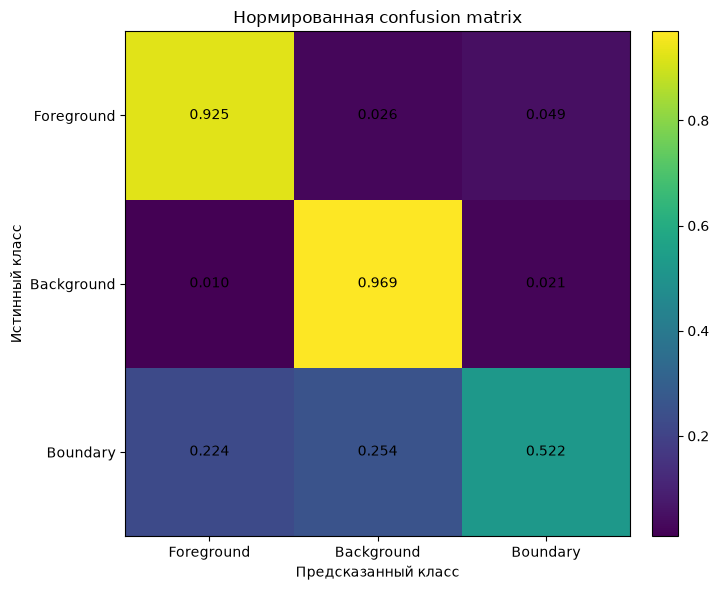

IoU по классам:
  Foreground  : 0.8355
  Background  : 0.9129
  Boundary    : 0.4237

Итоговый mIoU: 0.7240


In [12]:
# Переводим confusion matrix в numpy
cm = confusion_matrix.cpu().numpy().astype(float)

# Нормировка по строкам:
# каждая строка показывает распределение предсказаний
# для одного истинного класса
row_sums = cm.sum(axis=1, keepdims=True)
cm_normalized = np.divide(
    cm,
    row_sums,
    out=np.zeros_like(cm),
    where=row_sums != 0,
)

class_names = ["Foreground", "Background", "Boundary"]

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_normalized, interpolation="nearest")

ax.set_title("Нормированная confusion matrix")
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")

ax.set_xticks(np.arange(NUM_CLASSES))
ax.set_yticks(np.arange(NUM_CLASSES))
ax.set_xticklabels(class_names)
ax.set_yticklabels(class_names)

# Значения внутри ячеек
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(
            j,
            i,
            f"{cm_normalized[i, j]:.3f}",
            ha="center",
            va="center",
        )

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


# IoU по классам
print("IoU по классам:")
for class_name, value in zip(class_names, class_iou.cpu().tolist()):
    print(f"  {class_name:12s}: {value:.4f}")

print(f"\nИтоговый mIoU: {miou:.4f}")

### Совместное отражение и повторное обучение

*Вес: 1 балл.*

**Постановка.** Геометрическое преобразование изображения без идентичного преобразования маски портит разметку.

Выполните следующие действия:
1. Реализуйте синхронное горизонтальное отражение.
2. Обучите новый сегментатор при том же бюджете и сравните validation mIoU.

**Результат.** segmentation_aug.pt и augmentation_comparison.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [13]:
# Совместное отражение и повторное обучение
AUG_CHECKPOINT_PATH = ARTIFACTS / (
    "segmentation_aug_checkpoint_fast.pt"
    if FAST_DEV_RUN
    else "segmentation_aug_checkpoint.pt"
)

AUG_WEIGHTS_PATH = ARTIFACTS / (
    "segmentation_aug_fast.pt"
    if FAST_DEV_RUN
    else "segmentation_aug.pt"
)

AUG_COMPARISON_PATH = ARTIFACTS / (
    "augmentation_comparison_fast.json"
    if FAST_DEV_RUN
    else "augmentation_comparison.json"
)

AUG_EPOCHS = NUM_EPOCHS  # тот же бюджет, что и у baseline


# --- 1. Синхронное горизонтальное отражение ---

class RandomHorizontalFlipSegmentation(Dataset):
    def __init__(self, dataset, p=0.5, seed=SEED):
        self.dataset = dataset
        self.p = p
        self.seed = seed

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        image, mask = self.dataset[idx]

        # Детерминированный генератор для воспроизводимости
        rng = random.Random(self.seed + idx)

        if rng.random() < self.p:
            image = torch.flip(image, dims=[2])
            mask = torch.flip(mask, dims=[1])

        return image, mask


aug_train_ds = RandomHorizontalFlipSegmentation(
    train_ds,
    p=0.5,
    seed=SEED,
)

aug_loader = DataLoader(
    aug_train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE == "cuda"),
)

# Проверка синхронности:
test_image, test_mask = train_ds[0]
flipped_image = torch.flip(test_image, dims=[2])
flipped_mask = torch.flip(test_mask, dims=[1])

assert flipped_image.shape == test_image.shape
assert flipped_mask.shape == test_mask.shape

print("Synchronized horizontal flip: OK")


# --- 2. Создаём НОВЫЙ сегментатор ---

def create_segmentation_model():
    new_model = lraspp_mobilenet_v3_large(
        weights=LRASPP_MobileNet_V3_Large_Weights.DEFAULT
    )

    low_in = new_model.classifier.low_classifier.in_channels
    high_in = new_model.classifier.high_classifier.in_channels

    new_model.classifier.low_classifier = nn.Conv2d(
        low_in, NUM_CLASSES, kernel_size=1
    )
    new_model.classifier.high_classifier = nn.Conv2d(
        high_in, NUM_CLASSES, kernel_size=1
    )

    return new_model.to(DEVICE)


aug_model = create_segmentation_model()


# На CPU используем тот же режим обучения, что и для baseline
if DEVICE == "cpu":
    for param in aug_model.backbone.parameters():
        param.requires_grad = False
    AUG_TRAIN_MODE = "frozen_backbone"
else:
    for param in aug_model.backbone.parameters():
        param.requires_grad = True
    AUG_TRAIN_MODE = "full_finetune"


aug_optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, aug_model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

criterion = nn.CrossEntropyLoss()

aug_history = []
aug_start_epoch = 1
aug_best_val_loss = float("inf")


# --- 3. Resume / готовые веса ---

if AUG_WEIGHTS_PATH.exists() and AUG_COMPARISON_PATH.exists() and not FAST_DEV_RUN:
    print("Найдены готовые augmented weights. Обучение пропускается.")

    aug_model.load_state_dict(
        torch.load(
            AUG_WEIGHTS_PATH,
            map_location=DEVICE,
            weights_only=True,
        )
    )

    with open(AUG_COMPARISON_PATH, "r", encoding="utf-8") as f:
        aug_result = json.load(f)

    aug_history = aug_result["history"]
    aug_miou = aug_result["augmented_miou"]

else:
    if AUG_CHECKPOINT_PATH.exists() and not FAST_DEV_RUN:
        checkpoint = torch.load(
            AUG_CHECKPOINT_PATH,
            map_location=DEVICE,
            weights_only=False,
        )

        aug_model.load_state_dict(checkpoint["model_state_dict"])
        aug_optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

        aug_start_epoch = checkpoint["epoch"] + 1
        aug_history = checkpoint.get("history", [])
        aug_best_val_loss = checkpoint.get(
            "best_val_loss",
            float("inf"),
        )

        print(f"Продолжение с эпохи {aug_start_epoch}")
    else:
        print("Начало обучения augmented-модели с эпохи 1.")

    # --- 4. Обучение ---

    for epoch in range(aug_start_epoch, AUG_EPOCHS + 1):
        epoch_start = time.time()

        train_loss = train_one_epoch(
            model=aug_model,
            loader=aug_loader,
            optimizer=aug_optimizer,
            criterion=criterion,
            device=DEVICE,
        )

        val_loss = evaluate_loss(
            model=aug_model,
            loader=val_loader,
            criterion=criterion,
            device=DEVICE,
        )

        epoch_time = time.time() - epoch_start

        epoch_result = {
            "epoch": epoch,
            "train_loss": float(train_loss),
            "val_loss": float(val_loss),
            "time_seconds": float(epoch_time),
        }

        aug_history.append(epoch_result)
        aug_best_val_loss = min(aug_best_val_loss, val_loss)

        print(
            f"Epoch {epoch}/{AUG_EPOCHS} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"time={epoch_time:.1f}s"
        )

        # Checkpoint после каждой эпохи
        checkpoint = {
            "epoch": epoch,
            "model_state_dict": aug_model.state_dict(),
            "optimizer_state_dict": aug_optimizer.state_dict(),
            "best_val_loss": aug_best_val_loss,
            "history": aug_history,
            "config": {
                "augmentation": "horizontal_flip",
                "flip_probability": 0.5,
                "epochs": AUG_EPOCHS,
                "learning_rate": LEARNING_RATE,
                "weight_decay": WEIGHT_DECAY,
                "train_mode": AUG_TRAIN_MODE,
                "fast_dev_run": FAST_DEV_RUN,
            },
        }

        torch.save(checkpoint, AUG_CHECKPOINT_PATH)

    # --- 5. Validation mIoU augmented-модели ---

    aug_confusion = accumulate_confusion_matrix(
        model=aug_model,
        loader=val_loader,
        device=DEVICE,
        num_classes=NUM_CLASSES,
    )

    aug_tp = torch.diag(aug_confusion).float()
    aug_fp = aug_confusion.sum(dim=0).float() - aug_tp
    aug_fn = aug_confusion.sum(dim=1).float() - aug_tp
    aug_union = aug_tp + aug_fp + aug_fn

    aug_class_iou = torch.where(
        aug_union > 0,
        aug_tp / aug_union,
        torch.zeros_like(aug_union),
    )

    aug_valid_classes = aug_union > 0
    aug_miou = aug_class_iou[aug_valid_classes].mean().item()

    # --- 6. Сохраняем результат ---

    torch.save(
        aug_model.state_dict(),
        AUG_WEIGHTS_PATH,
    )

    # Если baseline JSON доступен — берём mIoU оттуда
    baseline_metrics_path = ARTIFACTS / (
        "val_metrics_fast.json"
        if FAST_DEV_RUN
        else "val_metrics.json"
    )

    if baseline_metrics_path.exists():
        with open(baseline_metrics_path, "r", encoding="utf-8") as f:
            baseline_metrics = json.load(f)
        baseline_miou = float(baseline_metrics["miou"])
    else:
        baseline_miou = float(miou)

    comparison = {
        "fast_dev_run": FAST_DEV_RUN,
        "baseline_miou": baseline_miou,
        "augmented_miou": float(aug_miou),
        "miou_difference": float(aug_miou - baseline_miou),
        "augmentation": {
            "type": "horizontal_flip",
            "probability": 0.5,
            "synchronized_image_and_mask": True,
        },
        "epochs": AUG_EPOCHS,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "train_mode": AUG_TRAIN_MODE,
        "history": aug_history,
        "weights": str(AUG_WEIGHTS_PATH),
        "checkpoint": str(AUG_CHECKPOINT_PATH),
    }

    with open(AUG_COMPARISON_PATH, "w", encoding="utf-8") as f:
        json.dump(
            comparison,
            f,
            ensure_ascii=False,
            indent=2,
        )

print("\nArtifacts:")
print("Weights:", AUG_WEIGHTS_PATH)
print("Comparison:", AUG_COMPARISON_PATH)

Synchronized horizontal flip: OK
Начало обучения augmented-модели с эпохи 1.
Epoch 1/5 | train_loss=0.2902 | val_loss=0.2578 | time=82.4s
Epoch 2/5 | train_loss=0.2561 | val_loss=0.2442 | time=82.1s
Epoch 3/5 | train_loss=0.2448 | val_loss=0.2436 | time=81.2s
Epoch 4/5 | train_loss=0.2364 | val_loss=0.2428 | time=82.2s
Epoch 5/5 | train_loss=0.2300 | val_loss=0.2472 | time=82.3s

Artifacts:
Weights: artifacts\segmentation_aug.pt
Comparison: artifacts\augmentation_comparison.json


In [14]:
# Итоговая информация об обучении augmented-модели
total_training_time_aug = sum(
    item["time_seconds"] for item in aug_history
)

total_parameters_aug = sum(
    p.numel() for p in aug_model.parameters()
)

trainable_parameters_aug = sum(
    p.numel()
    for p in aug_model.parameters()
    if p.requires_grad
)

final_train_loss_aug = aug_history[-1]["train_loss"]

print(f"Общее время обучения: {total_training_time_aug:.2f} сек.")
print(f"Всего параметров: {total_parameters_aug:,}")
print(f"Обучаемых параметров: {trainable_parameters_aug:,}")
print(f"Итоговый train loss: {final_train_loss_aug:.6f}")

# Итоговый вывод
print("\n" + "=" * 50)
print("СРАВНЕНИЕ BASELINE И AUGMENTATION")
print("=" * 50)
print(f"Baseline mIoU:    {baseline_miou:.4f}")
print(f"Augmented mIoU:   {aug_miou:.4f}")
print(f"Изменение mIoU:   {aug_miou - baseline_miou:+.4f}")
print("=" * 50)

Общее время обучения: 410.18 сек.
Всего параметров: 3,218,478
Обучаемых параметров: 246,526
Итоговый train loss: 0.230016

СРАВНЕНИЕ BASELINE И AUGMENTATION
Baseline mIoU:    0.7240
Augmented mIoU:   0.7259
Изменение mIoU:   +0.0019


### Сегментация малых объектов

*Вес: 1 балл.*

**Постановка.** Размер категории, заданный по train, позволяет отдельно изучать слабые места модели.

Выполните следующие действия:
1. Определите порог площади объекта только на train.
2. Вычислите foreground IoU на малых объектах validation для обеих моделей.

**Результат.** small_objects.json с размером подвыборки и IoU двух моделей.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [15]:
SMALL_OBJECTS_PATH = ARTIFACTS / (
    "small_objects_fast.json"
    if FAST_DEV_RUN
    else "small_objects.json"
)

# ---------------------------------------------------------
# 1. Площадь foreground для каждого изображения train
# ---------------------------------------------------------

def foreground_area(mask):
    """
    В нормализованной маске:
        0 = foreground
        1 = background
        2 = boundary
    """
    return int((mask == 0).sum().item())


train_areas = []

for i in range(len(train_ds)):
    _, mask = train_ds[i]
    train_areas.append(foreground_area(mask))

train_areas = np.asarray(train_areas, dtype=np.int64)

# Порог определяется ТОЛЬКО по train.
# Медиана делит train на две группы примерно одинакового размера.
small_area_threshold = float(np.median(train_areas))

print(f"Train foreground area:")
print(f"  min:    {train_areas.min()}")
print(f"  median: {small_area_threshold:.0f}")
print(f"  max:    {train_areas.max()}")


# ---------------------------------------------------------
# 2. Выбираем small objects из validation
# ---------------------------------------------------------

small_val_indices = []

for i in range(len(val_ds)):
    _, mask = val_ds[i]
    area = foreground_area(mask)

    if area <= small_area_threshold:
        small_val_indices.append(i)

print(f"\nSmall-object validation subset: {len(small_val_indices)}")


# ---------------------------------------------------------
# 3. Foreground IoU
# ---------------------------------------------------------

@torch.no_grad()
def foreground_iou_on_subset(model, dataset, indices, device):
    model.eval()

    ious = []

    for idx in indices:
        image, mask = dataset[idx]

        image_batch = image.unsqueeze(0).to(device)
        mask = mask.to(device)

        logits = model(image_batch)["out"]
        pred = logits.argmax(dim=1).squeeze(0)

        # Foreground = класс 0
        pred_fg = pred == 0
        target_fg = mask == 0

        intersection = (pred_fg & target_fg).sum().float()
        union = (pred_fg | target_fg).sum().float()

        if union > 0:
            iou = intersection / union
            ious.append(float(iou))

    if not ious:
        return float("nan"), 0

    return float(np.mean(ious)), len(ious)


# ---------------------------------------------------------
# 4. Small-object IoU для baseline
# ---------------------------------------------------------

baseline_small_iou, baseline_count = foreground_iou_on_subset(
    model=model,
    dataset=val_ds,
    indices=small_val_indices,
    device=DEVICE,
)


# ---------------------------------------------------------
# 5. Small-object IoU для augmented-модели
# ---------------------------------------------------------

augmented_small_iou, augmented_count = foreground_iou_on_subset(
    model=aug_model,
    dataset=val_ds,
    indices=small_val_indices,
    device=DEVICE,
)


# ---------------------------------------------------------
# 6. Сохраняем результат
# ---------------------------------------------------------

small_objects_result = {
    "fast_dev_run": FAST_DEV_RUN,
    "threshold_source": "train",
    "small_area_threshold_pixels": int(small_area_threshold),
    "train_objects_count": len(train_areas),
    "small_validation_subset_size": len(small_val_indices),
    "baseline_foreground_iou": baseline_small_iou,
    "augmented_foreground_iou": augmented_small_iou,
    "baseline_evaluated_count": baseline_count,
    "augmented_evaluated_count": augmented_count,
}

with open(SMALL_OBJECTS_PATH, "w", encoding="utf-8") as f:
    json.dump(
        small_objects_result,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ---------------------------------------------------------
# 7. Красивый вывод
# ---------------------------------------------------------

print("\n" + "=" * 55)
print("СЕГМЕНТАЦИЯ МАЛЫХ ОБЪЕКТОВ")
print("=" * 55)
print(f"Порог площади (определён по train): {small_area_threshold:.0f} px")
print(f"Размер validation-подвыборки:       {len(small_val_indices)}")
print()
print(f"Baseline foreground IoU:            {baseline_small_iou:.4f}")
print(f"Augmented foreground IoU:           {augmented_small_iou:.4f}")
print(
    f"Изменение:                           "
    f"{augmented_small_iou - baseline_small_iou:+.4f}"
)
print("=" * 55)

print(f"\nРезультат сохранён: {SMALL_OBJECTS_PATH}")

Train foreground area:
  min:    0
  median: 18194
  max:    59236

Small-object validation subset: 373

СЕГМЕНТАЦИЯ МАЛЫХ ОБЪЕКТОВ
Порог площади (определён по train): 18194 px
Размер validation-подвыборки:       373

Baseline foreground IoU:            0.7652
Augmented foreground IoU:           0.7639
Изменение:                           -0.0014

Результат сохранён: artifacts\small_objects.json


In [16]:
# Сравнение foreground IoU:
# вся validation vs малые объекты

# Foreground IoU на всей validation
all_val_indices = list(range(len(val_ds)))

baseline_fg_iou_all, _ = foreground_iou_on_subset(
    model=model,
    dataset=val_ds,
    indices=all_val_indices,
    device=DEVICE,
)

augmented_fg_iou_all, _ = foreground_iou_on_subset(
    model=aug_model,
    dataset=val_ds,
    indices=all_val_indices,
    device=DEVICE,
)


print("=" * 65)
print("FOREGROUND IoU: ВСЯ VALIDATION vs МАЛЫЕ ОБЪЕКТЫ")
print("=" * 65)

print(f"{'Модель':<15} {'Вся validation':>18} {'Малые объекты':>18}")
print("-" * 65)

print(
    f"{'Baseline':<15} "
    f"{baseline_fg_iou_all:>18.4f} "
    f"{baseline_small_iou:>18.4f}"
)

print(
    f"{'Augmented':<15} "
    f"{augmented_fg_iou_all:>18.4f} "
    f"{augmented_small_iou:>18.4f}"
)

print("-" * 65)

print(
    f"Baseline падение:   "
    f"{baseline_small_iou - baseline_fg_iou_all:+.4f}"
)

print(
    f"Augmented падение:  "
    f"{augmented_small_iou - augmented_fg_iou_all:+.4f}"
)

print("=" * 65)

FOREGROUND IoU: ВСЯ VALIDATION vs МАЛЫЕ ОБЪЕКТЫ
Модель              Вся validation      Малые объекты
-----------------------------------------------------------------
Baseline                    0.8129             0.7652
Augmented                   0.8083             0.7639
-----------------------------------------------------------------
Baseline падение:   -0.0477
Augmented падение:  -0.0444


### Отложенная оценка двух моделей

*Вес: 1 балл.*

**Постановка.** Test не должен влиять на обучение и выбор конфигурации.

Выполните следующие действия:
1. Загрузите test-раздел Oxford-IIIT Pet.
2. Оцените оба сохранённых сегментатора на одинаковых test-изображениях.

**Результат.** test_metrics.json с IoU на реальном test.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [17]:
TEST_METRICS_PATH = ARTIFACTS / (
    "test_metrics_fast.json"
    if FAST_DEV_RUN
    else "test_metrics.json"
)

# ---------------------------------------------------------
# 1. Загружаем test-раздел Oxford-IIIT Pet
# ---------------------------------------------------------

test_base_ds = OxfordIIITPet(
    root=DATA_ROOT,
    split="test",
    target_types="segmentation",
    download=True,
)

test_ds = NormalizedMaskDataset(
    OxfordPetSegmentation(
        test_base_ds,
        img_tf=img_tf,
        mask_tf=mask_tf,
    )
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE == "cuda"),
)

print("Test dataset size:", len(test_ds))


# ---------------------------------------------------------
# 2. Создаём функцию оценки модели
# ---------------------------------------------------------

@torch.no_grad()
def evaluate_test_miou(model, loader, device, num_classes=3):
    confusion = accumulate_confusion_matrix(
        model=model,
        loader=loader,
        device=device,
        num_classes=num_classes,
    )

    tp = torch.diag(confusion).float()
    fp = confusion.sum(dim=0).float() - tp
    fn = confusion.sum(dim=1).float() - tp

    union = tp + fp + fn

    class_iou = torch.where(
        union > 0,
        tp / union,
        torch.zeros_like(union),
    )

    valid_classes = union > 0
    miou = class_iou[valid_classes].mean().item()

    return {
        "miou": float(miou),
        "class_iou": class_iou.cpu().tolist(),
        "confusion_matrix": confusion.cpu().tolist(),
    }


# ---------------------------------------------------------
# 3. Загружаем сохранённые baseline и augmented модели
# ---------------------------------------------------------

baseline_weights = ARTIFACTS / (
    "segmentation_fast.pt"
    if FAST_DEV_RUN
    else "segmentation.pt"
)

augmented_weights = ARTIFACTS / (
    "segmentation_aug_fast.pt"
    if FAST_DEV_RUN
    else "segmentation_aug.pt"
)

# Baseline
test_baseline_model = create_segmentation_model()
test_baseline_model.load_state_dict(
    torch.load(
        baseline_weights,
        map_location=DEVICE,
        weights_only=True,
    )
)
test_baseline_model.eval()

# Augmented
test_augmented_model = create_segmentation_model()
test_augmented_model.load_state_dict(
    torch.load(
        augmented_weights,
        map_location=DEVICE,
        weights_only=True,
    )
)
test_augmented_model.eval()

print("Saved models loaded successfully.")


# ---------------------------------------------------------
# 4. Оцениваем обе модели на ОДНОМ test
# ---------------------------------------------------------

baseline_test = evaluate_test_miou(
    model=test_baseline_model,
    loader=test_loader,
    device=DEVICE,
    num_classes=NUM_CLASSES,
)

augmented_test = evaluate_test_miou(
    model=test_augmented_model,
    loader=test_loader,
    device=DEVICE,
    num_classes=NUM_CLASSES,
)


# ---------------------------------------------------------
# 5. Сохраняем test-метрики
# ---------------------------------------------------------

test_result = {
    "fast_dev_run": FAST_DEV_RUN,
    "test_dataset_size": len(test_ds),
    "num_classes": NUM_CLASSES,
    "baseline": {
        "miou": baseline_test["miou"],
        "class_iou": baseline_test["class_iou"],
        "confusion_matrix": baseline_test["confusion_matrix"],
        "weights": str(baseline_weights),
    },
    "augmented": {
        "miou": augmented_test["miou"],
        "class_iou": augmented_test["class_iou"],
        "confusion_matrix": augmented_test["confusion_matrix"],
        "weights": str(augmented_weights),
    },
    "miou_difference": (
        augmented_test["miou"] - baseline_test["miou"]
    ),
}

with open(TEST_METRICS_PATH, "w", encoding="utf-8") as f:
    json.dump(
        test_result,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ---------------------------------------------------------
# 6. Вывод результата
# ---------------------------------------------------------

print("\n" + "=" * 60)
print("ОТЛОЖЕННАЯ ОЦЕНКА НА TEST")
print("=" * 60)
print(f"Test images:       {len(test_ds)}")
print(f"Baseline mIoU:     {baseline_test['miou']:.4f}")
print(f"Augmented mIoU:    {augmented_test['miou']:.4f}")
print(
    f"Изменение mIoU:    "
    f"{augmented_test['miou'] - baseline_test['miou']:+.4f}"
)
print("=" * 60)

print(f"\nРезультат сохранён: {TEST_METRICS_PATH}")


Test dataset size: 3669
Saved models loaded successfully.

ОТЛОЖЕННАЯ ОЦЕНКА НА TEST
Test images:       3669
Baseline mIoU:     0.7250
Augmented mIoU:    0.7280
Изменение mIoU:    +0.0030

Результат сохранён: artifacts\test_metrics.json


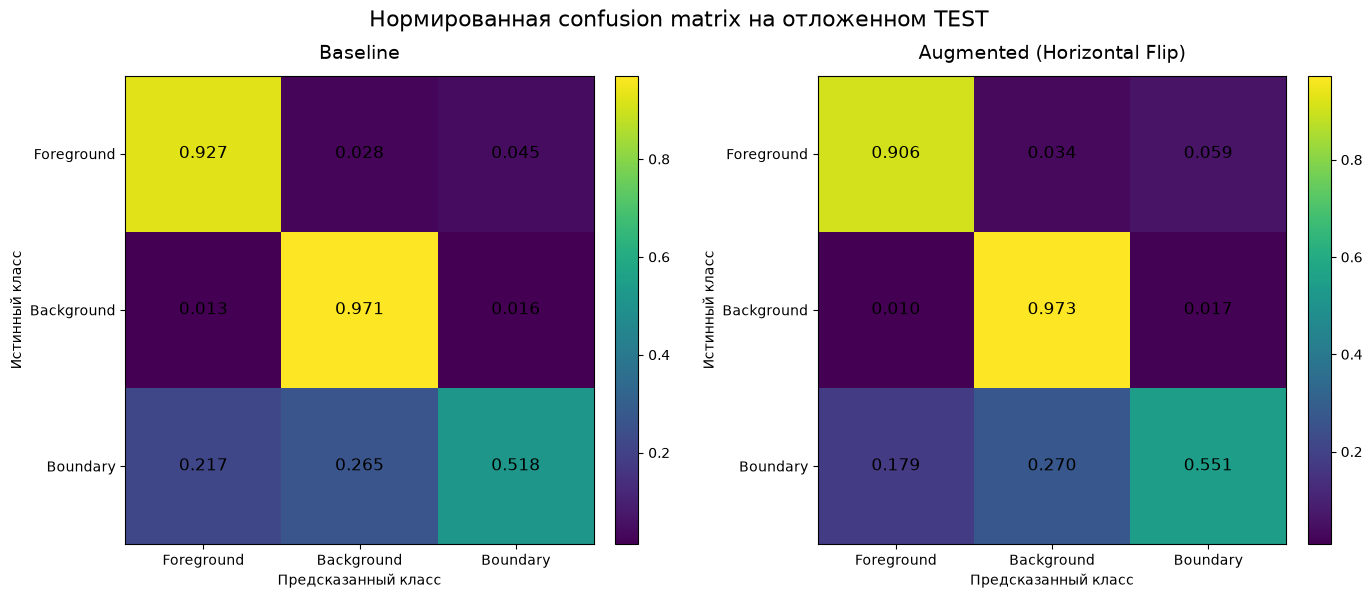

In [18]:
class_names = ["Foreground", "Background", "Boundary"]

def normalize_confusion_matrix(cm):
    cm = np.asarray(cm, dtype=float)
    row_sums = cm.sum(axis=1, keepdims=True)
    return np.divide(
        cm,
        row_sums,
        out=np.zeros_like(cm),
        where=row_sums != 0,
    )

baseline_cm = normalize_confusion_matrix(
    baseline_test["confusion_matrix"]
)
augmented_cm = normalize_confusion_matrix(
    augmented_test["confusion_matrix"]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

matrices = [
    (baseline_cm, "Baseline"),
    (augmented_cm, "Augmented (Horizontal Flip)"),
]

for ax, (cm, title) in zip(axes, matrices):
    im = ax.imshow(cm, interpolation="nearest")

    ax.set_title(title, fontsize=14, pad=12)
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")

    ax.set_xticks(np.arange(NUM_CLASSES))
    ax.set_yticks(np.arange(NUM_CLASSES))
    ax.set_xticklabels(class_names)
    ax.set_yticklabels(class_names)

    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(
                j,
                i,
                f"{cm[i, j]:.3f}",
                ha="center",
                va="center",
                fontsize=12,
            )

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle(
    "Нормированная confusion matrix на отложенном TEST",
    fontsize=16,
)
plt.tight_layout()
plt.show()

In [19]:
print("=" * 70)
print("TEST: IoU ПО КЛАССАМ И mIoU")
print("=" * 70)

print(f"{'Класс':<15} {'Baseline':>15} {'Augmented':>15}")
print("-" * 45)

for i, class_name in enumerate(class_names):
    print(
        f"{class_name:<15} "
        f"{baseline_test['class_iou'][i]:>15.4f} "
        f"{augmented_test['class_iou'][i]:>15.4f}"
    )

print("-" * 45)
print(
    f"{'mIoU':<15} "
    f"{baseline_test['miou']:>15.4f} "
    f"{augmented_test['miou']:>15.4f}"
)
print("=" * 70)

TEST: IoU ПО КЛАССАМ И mIoU
Класс                  Baseline       Augmented
---------------------------------------------
Foreground               0.8320          0.8293
Background               0.9062          0.9048
Boundary                 0.4368          0.4500
---------------------------------------------
mIoU                     0.7250          0.7280


### Локализация ошибок маски

*Вес: 1 балл.*

**Постановка.** False positive и false negative выделяют различные режимы сбоя сегментатора.

Выполните следующие действия:
1. Посчитайте IoU, FP и FN для каждого изображения validation.
2. Сохраните наиболее сложные изображения и их индексы.

**Результат.** error_analysis.json с фактическими ошибками модели.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


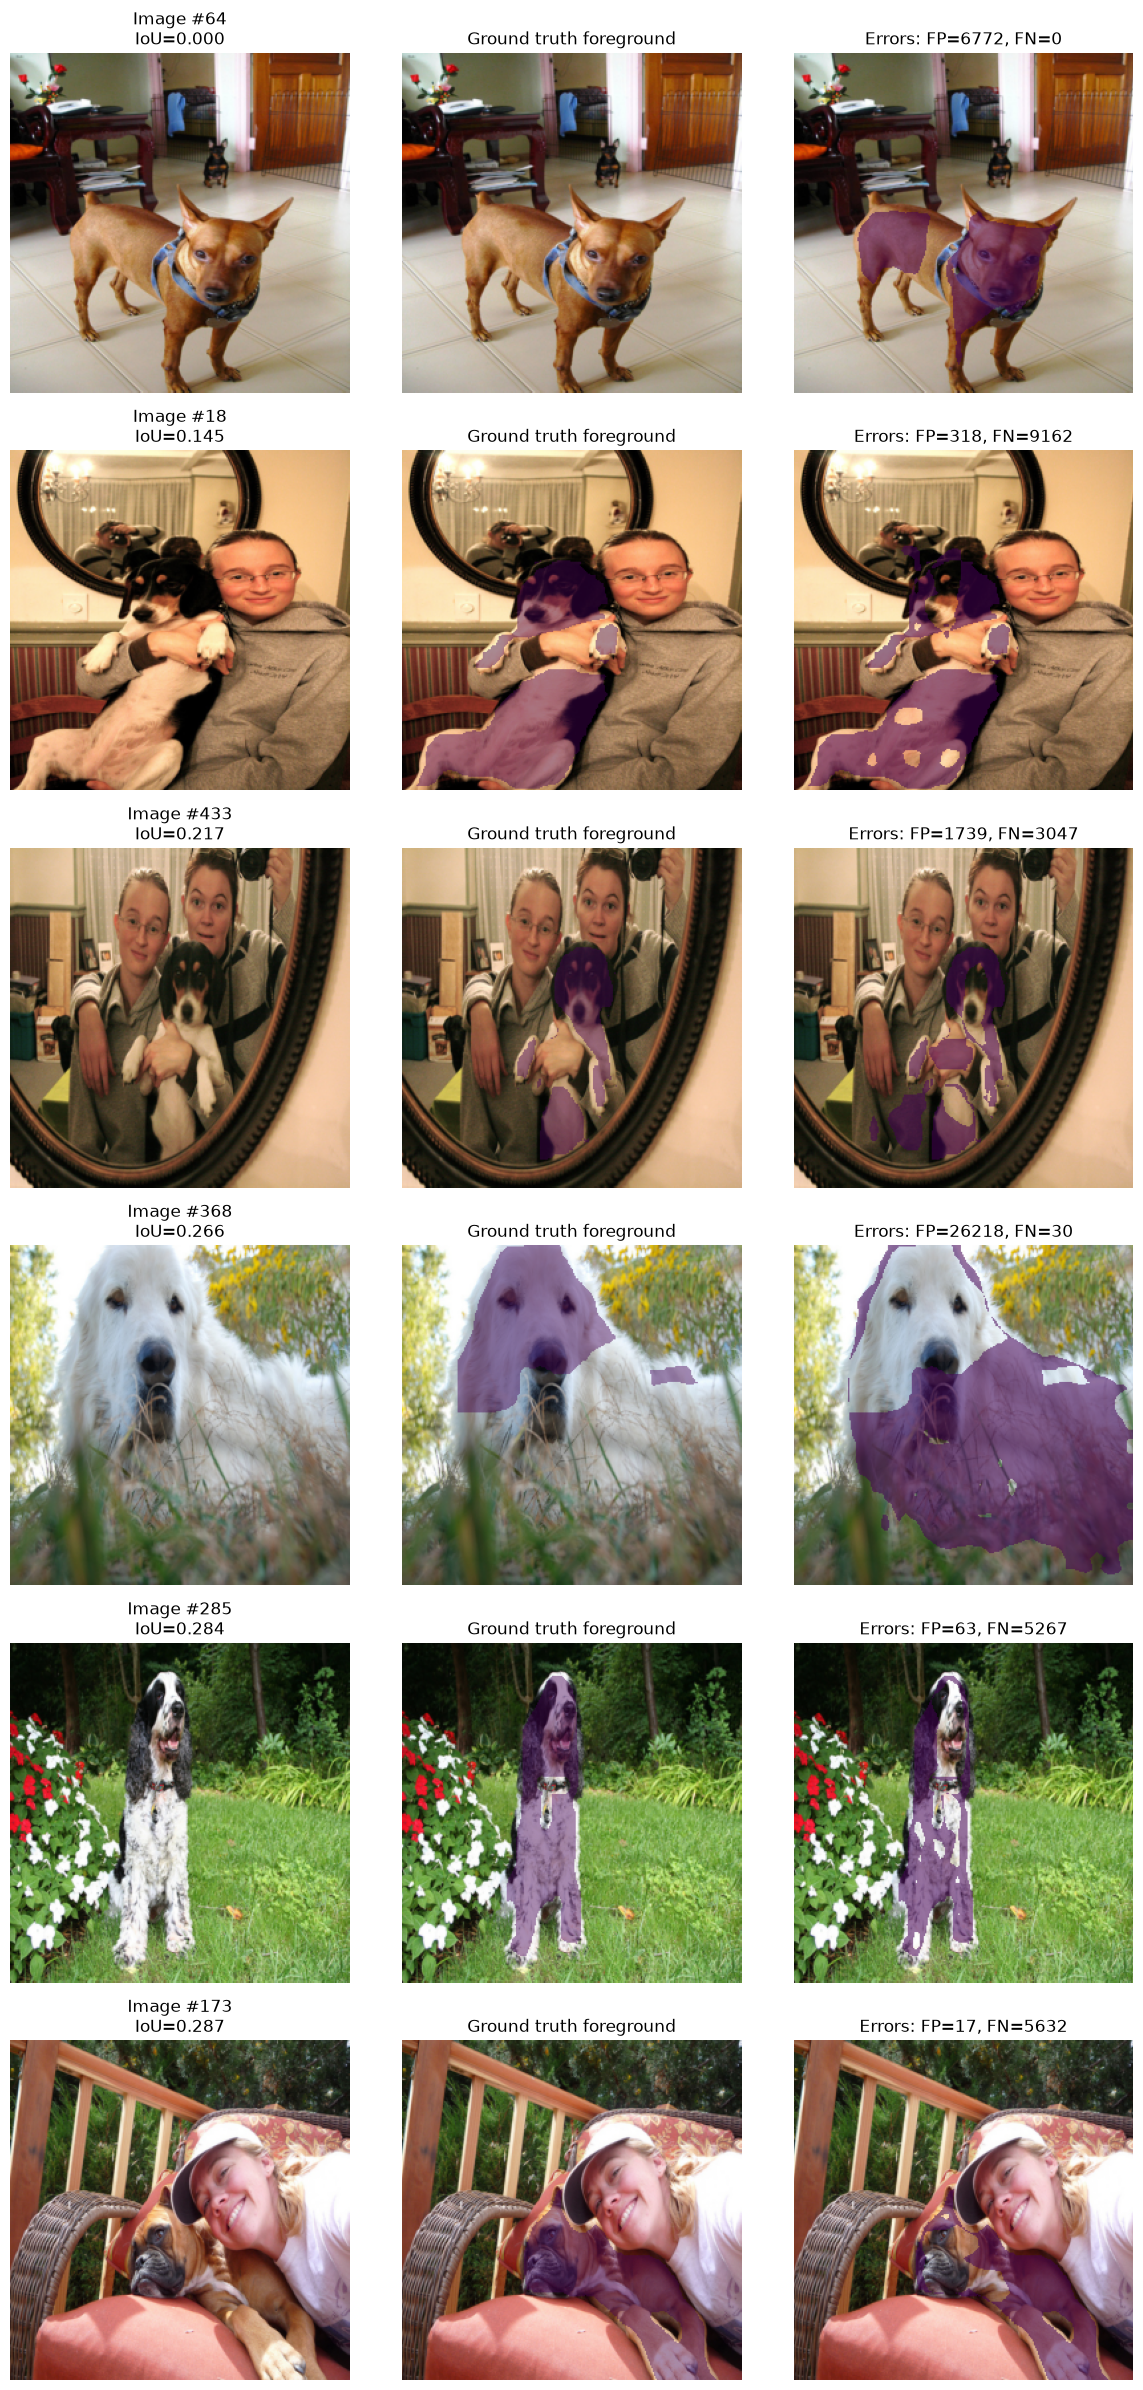


АНАЛИЗ ОШИБОК VALIDATION
Validation images: 736
Проанализировано:   736

Самые сложные изображения:
  idx=  64 | IoU=0.0000 | FP=  6772 | FN=     0
  idx=  18 | IoU=0.1446 | FP=   318 | FN=  9162
  idx= 433 | IoU=0.2170 | FP=  1739 | FN=  3047
  idx= 368 | IoU=0.2655 | FP= 26218 | FN=    30
  idx= 285 | IoU=0.2840 | FP=    63 | FN=  5267
  idx= 173 | IoU=0.2875 | FP=    17 | FN=  5632

Artifacts:
JSON: artifacts\error_analysis.json
Visualization: artifacts\error_examples.png


In [20]:
ERROR_ANALYSIS_PATH = ARTIFACTS / (
    "error_analysis_fast.json"
    if FAST_DEV_RUN
    else "error_analysis.json"
)

ERROR_IMAGES_PATH = ARTIFACTS / (
    "error_examples_fast.png"
    if FAST_DEV_RUN
    else "error_examples.png"
)

NUM_ERROR_EXAMPLES = 6


@torch.no_grad()
def analyze_validation_errors(model, dataset, device, num_examples=6):
    model.eval()

    results = []

    for idx in range(len(dataset)):
        image, mask = dataset[idx]

        image_device = image.unsqueeze(0).to(device)
        mask_device = mask.to(device)

        logits = model(image_device)["out"]
        pred = logits.argmax(dim=1).squeeze(0)

        # Анализируем foreground (класс 0)
        pred_fg = pred == 0
        target_fg = mask_device == 0

        tp = (pred_fg & target_fg).sum().item()
        fp = (pred_fg & ~target_fg).sum().item()
        fn = (~pred_fg & target_fg).sum().item()

        union = tp + fp + fn

        if union > 0:
            iou = tp / union
        else:
            iou = 1.0

        results.append({
            "dataset_index": int(idx),
            "iou": float(iou),
            "fp": int(fp),
            "fn": int(fn),
            "tp": int(tp),
        })

    # Чем меньше IoU, тем сложнее изображение.
    # При одинаковом IoU предпочтение отдаём большим ошибкам.
    results_sorted = sorted(
        results,
        key=lambda x: (x["iou"], -(x["fp"] + x["fn"])),
    )

    hardest = results_sorted[:num_examples]

    return results, hardest


all_errors, hardest_errors = analyze_validation_errors(
    model=model,
    dataset=val_ds,
    device=DEVICE,
    num_examples=NUM_ERROR_EXAMPLES,
)


# ---------------------------------------------------------
# Сохраняем изображения самых сложных случаев
# ---------------------------------------------------------

fig, axes = plt.subplots(
    len(hardest_errors),
    3,
    figsize=(12, 4 * len(hardest_errors)),
)

if len(hardest_errors) == 1:
    axes = np.expand_dims(axes, axis=0)

for row, error in enumerate(hardest_errors):
    idx = error["dataset_index"]

    image, mask = val_ds[idx]

    with torch.no_grad():
        logits = model(image.unsqueeze(0).to(DEVICE))["out"]
        pred = logits.argmax(dim=1).squeeze(0).cpu()

    image_np = image.permute(1, 2, 0).numpy()
    mask_np = mask.numpy()
    pred_np = pred.numpy()

    # 1. Исходное изображение
    axes[row, 0].imshow(image_np)
    axes[row, 0].set_title(
        f"Image #{idx}\nIoU={error['iou']:.3f}"
    )
    axes[row, 0].axis("off")

    # 2. Ground truth
    axes[row, 1].imshow(image_np)
    axes[row, 1].imshow(
        np.ma.masked_where(mask_np != 0, mask_np == 0),
        alpha=0.45,
    )
    axes[row, 1].set_title("Ground truth foreground")
    axes[row, 1].axis("off")

    # 3. Prediction + ошибки
    axes[row, 2].imshow(image_np)

    # FP — модель предсказала foreground, но GT его нет
    fp_mask = (pred_np == 0) & (mask_np != 0)

    # FN — foreground есть в GT, но модель его пропустила
    fn_mask = (pred_np != 0) & (mask_np == 0)

    axes[row, 2].imshow(
        np.ma.masked_where(~fp_mask, fp_mask),
        alpha=0.55,
    )
    axes[row, 2].imshow(
        np.ma.masked_where(~fn_mask, fn_mask),
        alpha=0.55,
    )

    axes[row, 2].set_title(
        f"Errors: FP={error['fp']}, FN={error['fn']}"
    )
    axes[row, 2].axis("off")

plt.tight_layout()
plt.savefig(ERROR_IMAGES_PATH, dpi=150, bbox_inches="tight")
plt.show()


# ---------------------------------------------------------
# Сохраняем фактические ошибки в JSON
# ---------------------------------------------------------

error_result = {
    "fast_dev_run": FAST_DEV_RUN,
    "model": "baseline",
    "validation_size": len(val_ds),
    "metric": "foreground IoU",
    "num_error_examples": len(hardest_errors),
    "hardest_indices": [
        item["dataset_index"]
        for item in hardest_errors
    ],
    "hardest_examples": hardest_errors,
    "all_image_errors": all_errors,
    "visualization": str(ERROR_IMAGES_PATH),
}

with open(ERROR_ANALYSIS_PATH, "w", encoding="utf-8") as f:
    json.dump(
        error_result,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ---------------------------------------------------------
# Вывод
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("АНАЛИЗ ОШИБОК VALIDATION")
print("=" * 70)
print(f"Validation images: {len(val_ds)}")
print(f"Проанализировано:   {len(all_errors)}")
print()

print("Самые сложные изображения:")
for item in hardest_errors:
    print(
        f"  idx={item['dataset_index']:4d} | "
        f"IoU={item['iou']:.4f} | "
        f"FP={item['fp']:6d} | "
        f"FN={item['fn']:6d}"
    )

print("\nArtifacts:")
print("JSON:", ERROR_ANALYSIS_PATH)
print("Visualization:", ERROR_IMAGES_PATH)
print("=" * 70)

### Поклассовая динамика аугментации

*Вес: 1 балл.*

**Постановка.** Средний IoU не показывает, каким классам помогло отражение.

Выполните следующие действия:
1. Сопоставьте поклассовый validation IoU исходной и дополненной моделей.
2. Сохраните изменения по каждому классу, не используя test для выбора модели.

**Результат.** class_deltas.json с наблюдаемыми изменениями IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [21]:
CLASS_DELTAS_PATH = ARTIFACTS / (
    "class_deltas_fast.json"
    if FAST_DEV_RUN
    else "class_deltas.json"
)

CLASS_NAMES = ["Foreground", "Background", "Boundary"]
NUM_CLASSES = len(CLASS_NAMES)


@torch.no_grad()
def validation_class_iou(model, loader, device, num_classes=3):
    """
    Считает IoU каждого класса на validation.
    Test здесь не используется.
    """
    confusion = accumulate_confusion_matrix(
        model=model,
        loader=loader,
        device=device,
        num_classes=num_classes,
    )

    tp = torch.diag(confusion).float()
    fp = confusion.sum(dim=0).float() - tp
    fn = confusion.sum(dim=1).float() - tp

    union = tp + fp + fn

    class_iou = torch.where(
        union > 0,
        tp / union,
        torch.zeros_like(union),
    )

    return class_iou.cpu().tolist(), confusion.cpu().tolist()


# ---------------------------------------------------------
# 1. Поклассовый IoU на ОДНОМ И ТОМ ЖЕ validation
# ---------------------------------------------------------

baseline_val_iou, baseline_val_cm = validation_class_iou(
    model=model,
    loader=val_loader,
    device=DEVICE,
    num_classes=NUM_CLASSES,
)

augmented_val_iou, augmented_val_cm = validation_class_iou(
    model=aug_model,
    loader=val_loader,
    device=DEVICE,
    num_classes=NUM_CLASSES,
)


# ---------------------------------------------------------
# 2. Изменение IoU после добавления horizontal flip
# ---------------------------------------------------------

class_deltas = []

for class_id, class_name in enumerate(CLASS_NAMES):
    baseline_iou = float(baseline_val_iou[class_id])
    augmented_iou = float(augmented_val_iou[class_id])
    delta = augmented_iou - baseline_iou

    class_deltas.append({
        "class_id": class_id,
        "class_name": class_name,
        "baseline_iou": baseline_iou,
        "augmented_iou": augmented_iou,
        "delta": float(delta),
    })


# ---------------------------------------------------------
# 3. Сохраняем артефакт
# ---------------------------------------------------------

result = {
    "fast_dev_run": FAST_DEV_RUN,
    "dataset": "Oxford-IIIT Pet",
    "split": "validation",
    "test_used_for_model_selection": False,
    "augmentation": {
        "type": "horizontal_flip",
        "probability": 0.5,
        "synchronized_image_and_mask": True,
    },
    "classes": CLASS_NAMES,
    "baseline": {
        "class_iou": baseline_val_iou,
        "confusion_matrix": baseline_val_cm,
    },
    "augmented": {
        "class_iou": augmented_val_iou,
        "confusion_matrix": augmented_val_cm,
    },
    "class_deltas": class_deltas,
}

with open(CLASS_DELTAS_PATH, "w", encoding="utf-8") as f:
    json.dump(result, f, ensure_ascii=False, indent=2)


# ---------------------------------------------------------
# 4. Красивый вывод
# ---------------------------------------------------------

print("=" * 75)
print("ПОКЛАССОВАЯ ДИНАМИКА АУГМЕНТАЦИИ — VALIDATION")
print("=" * 75)

print(
    f"{'Класс':<15}"
    f"{'Baseline IoU':>18}"
    f"{'Augmented IoU':>18}"
    f"{'Δ IoU':>15}"
)
print("-" * 75)

for item in class_deltas:
    print(
        f"{item['class_name']:<15}"
        f"{item['baseline_iou']:>18.4f}"
        f"{item['augmented_iou']:>18.4f}"
        f"{item['delta']:>+15.4f}"
    )

print("-" * 75)

baseline_miou_val = sum(baseline_val_iou) / len(baseline_val_iou)
augmented_miou_val = sum(augmented_val_iou) / len(augmented_val_iou)

print(
    f"{'mIoU':<15}"
    f"{baseline_miou_val:>18.4f}"
    f"{augmented_miou_val:>18.4f}"
    f"{augmented_miou_val - baseline_miou_val:>+15.4f}"
)

print("=" * 75)
print(f"Артефакт сохранён: {CLASS_DELTAS_PATH}")

ПОКЛАССОВАЯ ДИНАМИКА АУГМЕНТАЦИИ — VALIDATION
Класс                Baseline IoU     Augmented IoU          Δ IoU
---------------------------------------------------------------------------
Foreground                 0.8355            0.8294        -0.0061
Background                 0.9129            0.9098        -0.0031
Boundary                   0.4237            0.4385        +0.0149
---------------------------------------------------------------------------
mIoU                       0.7240            0.7259        +0.0019
Артефакт сохранён: artifacts\class_deltas.json


### Творческий бонус: диагностические маски

*Вес: 1 дополнительный балл.*

**Постановка.** Ошибки на границах полезно изучать в пространстве изображения.

Выполните следующие действия:
1. Найдите сложнейшее validation-изображение по IoU.
2. Сохраните реальную RGB-картинку, истинную и предсказанную маски для визуального разбора.

**Результат.** bonus_hard_case.png и bonus_hard_case.json с индексом и IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


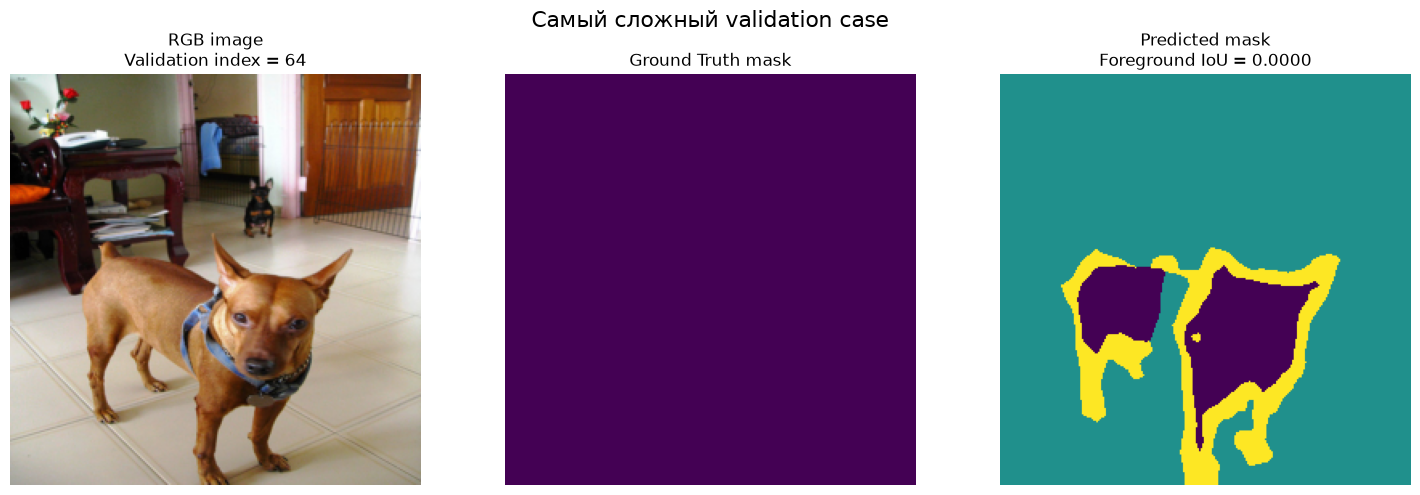

CREATIVE BONUS — DIAGNOSTIC MASKS
Самое сложное validation-изображение: #64
Foreground IoU: 0.0000

Artifacts:
  Image: artifacts\bonus_hard_case.png
  JSON:  artifacts\bonus_hard_case.json


In [22]:
BONUS_IMAGE_PATH = ARTIFACTS / "bonus_hard_case.png"
BONUS_JSON_PATH = ARTIFACTS / "bonus_hard_case.json"


@torch.no_grad()
def find_hardest_validation_case(model, dataset, device):
    model.eval()

    hardest = None

    for idx in range(len(dataset)):
        image, mask = dataset[idx]

        image_device = image.unsqueeze(0).to(device)
        mask_device = mask.to(device)

        logits = model(image_device)["out"]
        pred = logits.argmax(dim=1).squeeze(0)

        # Foreground = class 0
        pred_fg = pred == 0
        target_fg = mask_device == 0

        intersection = (pred_fg & target_fg).sum().item()
        union = (pred_fg | target_fg).sum().item()

        iou = intersection / union if union > 0 else 1.0

        if hardest is None or iou < hardest["iou"]:
            hardest = {
                "dataset_index": int(idx),
                "iou": float(iou),
                "image": image.cpu(),
                "mask": mask.cpu(),
                "prediction": pred.cpu(),
            }

    return hardest


# ---------------------------------------------------------
# 1. Ищем самое сложное validation-изображение
# ---------------------------------------------------------

hard_case = find_hardest_validation_case(
    model=model,
    dataset=val_ds,
    device=DEVICE,
)

hard_idx = hard_case["dataset_index"]
hard_iou = hard_case["iou"]

image = hard_case["image"]
true_mask = hard_case["mask"]
pred_mask = hard_case["prediction"]


# ---------------------------------------------------------
# 2. Подготавливаем RGB, Ground Truth и Prediction
# ---------------------------------------------------------

image_np = image.permute(1, 2, 0).numpy()
true_mask_np = true_mask.numpy()
pred_mask_np = pred_mask.numpy()


# ---------------------------------------------------------
# 3. Сохраняем визуализацию
# ---------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_np)
axes[0].set_title(
    f"RGB image\nValidation index = {hard_idx}"
)
axes[0].axis("off")

axes[1].imshow(true_mask_np)
axes[1].set_title("Ground Truth mask")
axes[1].axis("off")

axes[2].imshow(pred_mask_np)
axes[2].set_title(
    f"Predicted mask\nForeground IoU = {hard_iou:.4f}"
)
axes[2].axis("off")

plt.suptitle(
    "Самый сложный validation case",
    fontsize=16,
)

plt.tight_layout()
plt.savefig(
    BONUS_IMAGE_PATH,
    dpi=150,
    bbox_inches="tight",
)
plt.show()


# ---------------------------------------------------------
# 4. Сохраняем JSON с индексом и IoU
# ---------------------------------------------------------

bonus_result = {
    "fast_dev_run": FAST_DEV_RUN,
    "split": "validation",
    "model": "baseline",
    "metric": "foreground IoU",
    "hardest_validation_index": hard_idx,
    "iou": hard_iou,
    "image": str(BONUS_IMAGE_PATH),
}

with open(BONUS_JSON_PATH, "w", encoding="utf-8") as f:
    json.dump(
        bonus_result,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ---------------------------------------------------------
# 5. Итог
# ---------------------------------------------------------

print("=" * 70)
print("CREATIVE BONUS — DIAGNOSTIC MASKS")
print("=" * 70)
print(f"Самое сложное validation-изображение: #{hard_idx}")
print(f"Foreground IoU: {hard_iou:.4f}")
print()
print("Artifacts:")
print(f"  Image: {BONUS_IMAGE_PATH}")
print(f"  JSON:  {BONUS_JSON_PATH}")
print("=" * 70)

## Анализ результатов

В ходе работы была обучена исходная модель сегментации и модель с горизонтальным отражением изображений. На проверочной выборке исходная модель получила mIoU = 0.724, а модель с аугментацией — 0.726, то есть результат практически не изменился. При анализе по классам видно, что отражение больше всего повлияло на класс Boundary, где IoU изменился с 0.424 до 0.439. На отложенной тестовой выборке результат составил 0.725 для исходной модели и 0.728 для модели с аугментацией. Самые большие ошибки наблюдались на изображениях с животными, части которых перекрывают детали (руки, ветки, трава)